In [49]:
pip install z3-solver


[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Puzzle to solve
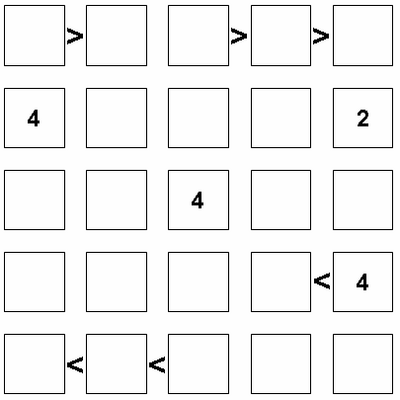
Puzzle solved
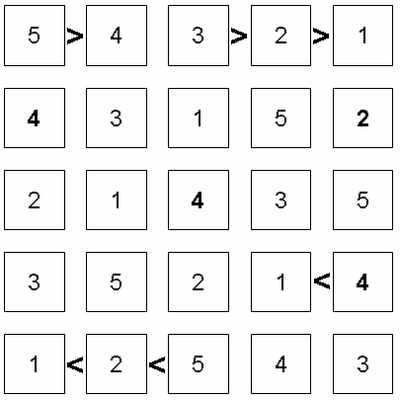

In [53]:
from z3 import *

# Initialize the Z3 solver
#solver = Solver()
solver = Then('simplify','solve-eqs','bit-blast', 'sat').solver()

# Define the size of the grid (nxn)
n = 5

# Create a nxn grid where each cell is a Z3 variable
#grid = [[Int(f"cell_{r}_{c}") for c in range(n)] for r in range(n)]
grid = [[BitVec(f"cell_{r}_{c}",8) for c in range(n)] for r in range(n)]

# Add constraints: Each cell must contain a value from 1 to n
for r in range(n):
    for c in range(n):
        solver.add(And(grid[r][c] >= 1, grid[r][c] <= n))

# Add constraints: Each row and column must have distinct values
for r in range(n):
    #solver.add(Distinct(grid[r]))  # Ensure distinct values in rows
    for i in range(len(grid[r])):
       for j in range(i + 1, len(grid[r])):
           solver.add(grid[r][i] != grid[r][j])

for c in range(n):
    #solver.add(Distinct([grid[r][c] for r in range(n)]))  # Ensure distinct values in columns
    for i in range(len(grid)):
        for j in range(i + 1, len(grid)):
            solver.add(grid[i][c] != grid[j][c])  # Ensure grid[i][c] != grid[j][c]
    
# Add some inequality constraints (e.g., cell (0,0) > cell (0,1))
solver.add(grid[0][1] < grid[0][0])
solver.add(grid[0][3] < grid[0][2])
solver.add(grid[0][4] < grid[0][3])
solver.add(grid[3][3] < grid[3][4])
solver.add(grid[4][0] < grid[4][1])
solver.add(grid[4][1] < grid[4][2])

solver.add(grid[1][0] == 4)
solver.add(grid[2][2] == 4)
solver.add(grid[1][4] == 2)
solver.add(grid[3][4] == 4)

#print(solver.sexpr())
#print(solver.to_smt2())

# Try to solve the puzzle
if solver.check() == sat:
    model = solver.model()
    # Print the solution (the value in each cell)
    for r in range(n):
        print([model[grid[r][c]] for c in range(n)])
else:
    print("No solution found.")


[5, 4, 3, 2, 1]
[4, 3, 1, 5, 2]
[2, 1, 4, 3, 5]
[3, 5, 2, 1, 4]
[1, 2, 5, 4, 3]
